# CRA 漏洞全生命周期 · 基本全流程演示

对应研究报告 **`report/10-maps.md` 图 B**（发现/关联 → 判定 → 处置 → 报告/留证，底栏 Evidence Graph），
逐段验证 **`report/04`** 的 5 个 User Journey 与 **`report/08`** 的 PoC-1/2/3/4 微缩闭环。

**演示产品**：Acme IoT Gateway v3.2.1（虚构，欧盟"含数字元素"产品制造商场景）

| 阶段 | 本笔记本内容 | 法条锚点（图 A） |
|------|-------------|------------------|
| ① 摄取 | 产品台账（支持期≥5 年）+ SBOM + 质量分 | Annex I Pt II(1)(3) |
| ② 关联 | 多源情报归一、别名消解、区间匹配、backport 覆写（**五层透明**）| Annex I Pt II(1) |
| ③ 判定 | L2 Reachability（call path 证据）+ Exploitability 四轴证据卡 | "exploitable" 推导 |
| ④ VEX | 状态机 affected/not_affected/fixed/investigating + justification + 强制证据 + SLA | VEX 语义（01 §6）|
| ⑤ 处置 | 修复四选 → 升级 → 复扫验证 → fixed | Annex I Pt II(2)(4) |
| ⑥ 报告 | 事件状态机 24h/72h/14d + SBOM 快照冻结 | **Art.14（2026-09-11 已生效）** |
| ⑦ 留证 | Evidence Graph 建图 / 时间旅行查询 / 客户应答包导出 | Annex I Pt II(6) 记录 ≥10 年 |

> **数据诚实声明**：情报/KEV/EPSS/版本区间均为**演示夹具（FIXTURE）**，模拟真实源的结构与语义，
> **不代替实时情报**（其中 Log4Shell / PwnKit / 45046 为真实历史 CVE，数值已简化）。
> 生产实现见 `report/05`（真源接入）与 `report/08` PoC-1/2 验收标准。

**自行运行**：
```bash
.venv/bin/jupyter lab demo/cra_lifecycle_demo.ipynb     # 交互
.venv/bin/python demo/build_notebook.py                 # 无头重建+执行
```

---

## 📖 阅读导航（从上到下即完整故事线）

| 顺序 | 章节 | 一句话结论（先读这个） |
|------|------|------------------------|
| ① | 摄取与盘点 | CRA 要的不是扫描表，是**产品档案**（支持期+SBOM 台账） |
| ② | 归一与关联 | 多源打架时**把五层证据摊开**——发行版已修的假阳性当场拦下 |
| ③A | 判定 · 可达性 | 问的不是"有没有 CVE"，是"**代码路径能不能被打进来**" |
| ③B | 判定 · 四轴 | 四轴证据并排 + **透明规则**，不给黑箱分数 |
| ④ | VEX 工作流 | 每个判定**必须带理由和证据**，超时 24h 自动升级 |
| ⑤ | 处置与验证 | 标 `fixed` 前**必须复扫**——上游修了 ≠ 我的产品修了 |
| ⑥ | 事件报告 | KEV 触发 **24h 法定报告**——时钟+字段+冻结快照已就位 |
| ⑦ | 留证 | 全程沉淀**10 年可回放证据图**，客户材料 2 分钟装配 |
| ⑧ | 收尾 | 阶段 × 法条 × 产物总表（图 A/B 对照） |

> 代码默认折叠：点单元格左侧 **[ ]** 或输出上方的输入区可展开；评审时只看 **加粗结论 + 表 + 图** 即可。
> 更适合投屏的版本：`demo/presentation.html`（浏览器直接打开，←/→ 翻页）。


## 0 · 环境与确定性配置

In [1]:
%matplotlib inline
from __future__ import annotations

import hashlib
import json
import re
from datetime import datetime, timedelta, timezone
from pathlib import Path

import matplotlib
import networkx as nx
import pandas as pd
from matplotlib import font_manager, pyplot as plt

matplotlib.use("module://matplotlib_inline.backend_inline")

OUT = Path("out")
OUT.mkdir(exist_ok=True)

_CJK = Path.home() / ".fonts/NotoSansCJKsc-Regular.otf"
if _CJK.exists():
    font_manager.fontManager.addfont(str(_CJK))
    matplotlib.rcParams["font.family"] = "Noto Sans CJK SC"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

TZ = timezone(timedelta(hours=8))
T0 = datetime(2026, 9, 22, 10, 0, tzinfo=TZ)   # 事件 T0（演示时钟）
T_CHECK = T0 + timedelta(hours=6)               # 24h 草稿产出时刻
T_LATE = T0 + timedelta(hours=30)               # SLA 检查时刻（A4 超时）


def sid(*parts) -> str:
    # 内容寻址快照 ID：可回放、防篡改（report 06 §4.2）
    raw = "|".join(str(p) for p in parts)
    return "snap-" + hashlib.sha256(raw.encode()).hexdigest()[:12]


def save(name: str, obj) -> Path:
    p = OUT / name
    p.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"  ✔ {p}  ({p.stat().st_size:,} bytes)")
    return p


def num_tuple(v: str):
    m = re.match(r"(\d+(?:\.\d+)*)", v)
    return tuple(int(x) for x in m.group(1).split(".")) if m else (0,)


def _pad(a, b):
    n = max(len(a), len(b))
    return a + (0,) * (n - len(a)), b + (0,) * (n - len(b))


def in_range(version: str, range_str: str) -> bool:
    # 简化区间求值（演示用；生产按生态原生比较器，见 report 01 §4.2）
    a = num_tuple(version)
    for op, ver in re.findall(r"(>=|<=|>|<|=)\s*([0-9][0-9A-Za-z.\-+]*)", range_str):
        b = num_tuple(ver)
        aa, bb = _pad(a, b)
        ok = { "<": aa < bb, "<=": aa <= bb, ">": aa > bb, ">=": aa >= bb, "=": aa == bb }[op]
        if not ok:
            return False
    return True


print("T0 =", T0.isoformat(), "| 输出目录 =", OUT.resolve())


T0 = 2026-09-22T10:00:00+08:00 | 输出目录 = demo/out


## ① 摄取与盘点 — 产品台账 + SBOM

> **一句话结论：** CRA 要的不是一张扫描表，是**产品档案**——先把"卖什么、保多久、里面装了什么"登记成台账，后面所有判定都挂在这份档案上。

- 法条：**Annex I Pt II(1)** SBOM（至少顶层依赖、机器可读）+ **Pt II(3)** 支持期默认 ≥5 年
- Journey：**J1** 新产品上线合规体检（`report/04 §4`）
- 产品级模型（Product × Release × 支持期）是一等公民 —— `report/03 §5`


In [2]:
PRODUCT = {
    "name": "Acme IoT Gateway",
    "version": "3.2.1",
    "support_until": "2031-06-30",          # ≥5 年支持期（Annex I Pt II(3)）
    "reporting_live": True,                 # Art.14 自 2026-09-11 已生效
    "manufacturer": "Acme Devices GmbH (EU)",
}

SBOM_V321 = {
    "format": "CycloneDX-1.7 (demo subset)",
    "product": PRODUCT["name"],
    "release": PRODUCT["version"],
    "components": [
        {"purl": "pkg:maven/org.apache.logging.log4j/log4j-core", "version": "2.14.0", "scope": "direct", "licenses": ["Apache-2.0"]},
        {"purl": "pkg:maven/org.eclipse.jetty/jetty-server", "version": "9.4.44.v20210927", "scope": "direct", "licenses": ["Apache-2.0"]},
        {"purl": "pkg:maven/com.acme/telemetry-sdk", "version": "1.4.2", "scope": "direct", "licenses": ["MIT"]},
        {"purl": "pkg:deb/debian/policykit-1", "version": "0.105-33+deb11u1", "scope": "transitive", "licenses": ["GPL-2.0"]},
    ],
}
sbom_snap = sid("sbom", PRODUCT["version"], json.dumps(SBOM_V321, sort_keys=True))
SBOM_V321["snapshot_id"] = sbom_snap
SBOM_V321["generated_at"] = T0.isoformat()


def sbom_quality(sbom: dict) -> dict:
    # SBOM 质量分（report 05/03：质量=隐藏卖点）
    checks = {
        "有 PURL": all(c.get("purl") for c in sbom["components"]),
        "有版本": all(c.get("version") for c in sbom["components"]),
        "标注 scope": all(c.get("scope") in {"direct", "transitive"} for c in sbom["components"]),
        "有许可证": all(c.get("licenses") for c in sbom["components"]),
        "支持期已声明": bool(PRODUCT.get("support_until")),
    }
    return {"score": sum(checks.values()) * 20, "checks": checks}


q = sbom_quality(SBOM_V321)
sbom_snap = sid("sbom-quality", PRODUCT["version"], q["score"])

print(f"产品: {PRODUCT['name']} v{PRODUCT['version']}  支持期至 {PRODUCT['support_until']} (≥5 年 ✓)")
print(f"SBOM 快照: {sbom_snap}  组件数: {len(SBOM_V321['components'])}")
print(f"SBOM 质量分: {q['score']}/100")
pd.DataFrame([{"检查项": k, "结果": "✅" if v else "❌"} for k, v in q["checks"].items()]).style.hide(axis="index")


产品: Acme IoT Gateway v3.2.1  支持期至 2031-06-30 (≥5 年 ✓)
SBOM 快照: snap-f07fc15cbc73  组件数: 4
SBOM 质量分: 100/100


检查项,结果
有 PURL,✅
有版本,✅
标注 scope,✅
有许可证,✅
支持期已声明,✅


## ② 归一与关联 — 多源情报、五层透明匹配

> **一句话结论：** 同一漏洞多个来源结论不一致时，我们**不静默选一个**，而是把五层证据（源/区间/backport/别名/时间）摊开——PwnKit 这种"发行版其实已修"的假阳性当场被拦下。

对应 **PoC-1**（`report/08 §3`）与 `report/03 §2` 五层不确定性。

本阶段四个告警（fixtures）：

| ID | CVE | 组件 | 故事 |
|----|-----|------|------|
| A1 | CVE-2021-44228 Log4Shell | log4j-core 2.14.0 | 多源一致命中 + KEV → 后续触发事件报告 |
| A2 | CVE-2021-45046 | log4j-core 2.14.0 | 同组件、不同 CVE → **不可达** → VEX not_affected |
| A3 | CVE-2021-4034 PwnKit | policykit-1 (deb) | NVD 区间假阳性 + **Debian backport 覆写** |
| A4 | CVE-2026-42424（**合成**） | telemetry-sdk 1.4.2 | 新情报、未分析 → under_investigation + SLA |


In [3]:
INTEL = [
    {
        "id": "A1", "cve": "CVE-2021-44228",
        "aliases": ["GHSA-jfh8-c2jp-5v3q", "OSV-2020-1613"],
        "title": "Log4Shell — JNDI lookup RCE",
        "component_purl": "pkg:maven/org.apache.logging.log4j/log4j-core",
        "sources": [
            {"src": "NVD", "range": ">=2.0-beta9 <2.15.0", "cvss": 10.0, "cwe": "CWE-502"},
            {"src": "OSV", "range": ">=2.0-beta9 <2.15.0"},
            {"src": "GHSA", "range": ">=2.0-beta9 <2.15.0", "fixed": "2.15.0"},
        ],
        "kev": True, "epss": 0.976, "actively_exploited": True,
        "fix_version": "2.17.1", "published": "2021-12-10",
    },
    {
        "id": "A2", "cve": "CVE-2021-45046",
        "aliases": ["GHSA-ajwx-c52v-5m3g"],
        "title": "Log4j2 incomplete fix — pattern lookup",
        "component_purl": "pkg:maven/org.apache.logging.log4j/log4j-core",
        "sources": [
            {"src": "NVD", "range": ">=2.0-beta9 <2.15.1", "cvss": 9.0},
            {"src": "OSV", "range": ">=2.0-beta9 <2.15.1"},
        ],
        "kev": False, "epss": 0.214, "actively_exploited": False,
        "fix_version": "2.16.0", "published": "2021-12-14",
    },
    {
        "id": "A3", "cve": "CVE-2021-4034",
        "aliases": ["PwnKit"],
        "title": "pkexec PwnKit LPE",
        "component_purl": "pkg:deb/debian/policykit-1",
        "sources": [
            {"src": "NVD", "range": ">=0.105 <0.120", "cvss": 7.8},
        ],
        "distro": {  # Debian security tracker 语义（backport 真相源，report 01 §4.2）
            "tracker": "https://security-tracker.debian.org/tracker/CVE-2021-4034",
            "suite": "bullseye",
            "status": "fixed",
            "fixed_in": "0.105-33+deb11u1",   # backport 已并入我们镜像的版本
        },
        "kev": True, "epss": 0.941, "actively_exploited": True,
        "fix_version": None, "published": "2022-01-25",
    },
    {
        "id": "A4", "cve": "CVE-2026-42424",  # ⚠ 合成夹具
        "aliases": ["GHSA-xxxx-SYNTH"],
        "title": "[SYNTHETIC] telemetry-sdk 反序列化缺陷（演示用）",
        "component_purl": "pkg:maven/com.acme/telemetry-sdk",
        "sources": [
            {"src": "NVD", "range": ">=1.4.0 <1.4.3", "cvss": 8.1},
        ],
        "kev": False, "epss": 0.062, "actively_exploited": False,
        "fix_version": "1.4.3", "published": "2026-09-21",
    },
]


def associate(sbom: dict, intel: list) -> pd.DataFrame:
    # 五层关联：数据源→区间→backport→别名→及时性（每层可解释）
    comp_by_purl = {c["purl"]: c for c in sbom["components"]}
    rows = []
    for it in intel:
        comp = comp_by_purl.get(it["component_purl"])
        if not comp:
            rows.append({"alert": it["id"], "cve": it["cve"], "match": "组件不在 SBOM",
                         "hit": False, "layer3_distro": "-", "sources": len(it["sources"]), "epss": it["epss"], "kev": it["kev"]})
            continue
        ver = comp["version"]
        hits = [in_range(ver, s["range"]) for s in it["sources"]]
        ranges = {s["range"] for s in it["sources"]}
        l1 = "多源一致" if len(ranges) == 1 and all(hits) else ("区间分歧" if len(ranges) > 1 else "单源")
        l2 = all(hits)  # 全部源均命中才进入深判
        distro = it.get("distro")
        if distro:
            l3 = f"distro:{distro['status']} @{distro['fixed_in']}"
            hit = distro["status"] == "affected"  # 覆写：backport fixed → 不再视为命中
        else:
            l3 = "—"
            hit = l2
        rows.append({
            "alert": it["id"], "cve": it["cve"], "component": comp["purl"].split("/")[-1],
            "version": ver, "match": "版本区间命中" if l2 else "未命中",
            "L1源": l1, "L3_distro": l3, "别名": "+".join(it["aliases"][:1]) or "-",
            "hit": hit, "kev": it["kev"], "epss": it["epss"],
            "published": it["published"],
        })
    return pd.DataFrame(rows)


alerts = associate(SBOM_V321, INTEL)
intel_snap = sid("intel", *[i["cve"] for i in INTEL], T0.isoformat())
print(f"情报快照: {intel_snap}   |  告警数: {len(alerts)}")
alerts.style.hide(axis="index")


情报快照: snap-386da88c38db   |  告警数: 4


alert,cve,component,version,match,L1源,L3_distro,别名,hit,kev,epss,published
A1,CVE-2021-44228,log4j-core,2.14.0,版本区间命中,多源一致,—,GHSA-jfh8-c2jp-5v3q,True,True,0.976000,2021-12-10
A2,CVE-2021-45046,log4j-core,2.14.0,版本区间命中,多源一致,—,GHSA-ajwx-c52v-5m3g,True,False,0.214000,2021-12-14
A3,CVE-2021-4034,policykit-1,0.105-33+deb11u1,版本区间命中,多源一致,distro:fixed @0.105-33+deb11u1,PwnKit,False,True,0.941000,2022-01-25
A4,CVE-2026-42424,telemetry-sdk,1.4.2,版本区间命中,多源一致,—,GHSA-xxxx-SYNTH,True,False,0.062000,2026-09-21


## ③A 判定 · Reachability（L2 call path 证据）

> **一句话结论：** 问的不是"有没有 CVE"，而是"**这段有漏洞的代码，攻击者能不能从外部打进来**"——一条画出来的调用路径，就是给审计师看的答案。

- 对应 **PoC-2**（`report/05 §7` 验收：真不可达识别 + 可视化 path）
- 结论直接映射 VEX justification：不可达 → `vulnerable_code_not_in_execute_path`（`report/05 §5`）
- A3 是发行版级 backport（无 call path），A4 待分析（SLA 阶段再看）


findfont: Failed to find font weight bold for Noto Sans CJK SC, now using 400.


A1: REACHABLE ✓ → 路径: HTTP /api/ingest → IngestServlet.doPost → LogUtil.logEvent → Logger.error(msg) → MessagePatternConverter.format → JndiLookup.lookup()  [VULN]   [snap-6b53a678e631]
A2: UNREACHABLE ✗ (外部入口无路径)   [snap-4d5a3b9156bc]
A3: 未分析（发行版级/无源码调用图输入）→ under_investigation
A4: 未分析（发行版级/无源码调用图输入）→ under_investigation


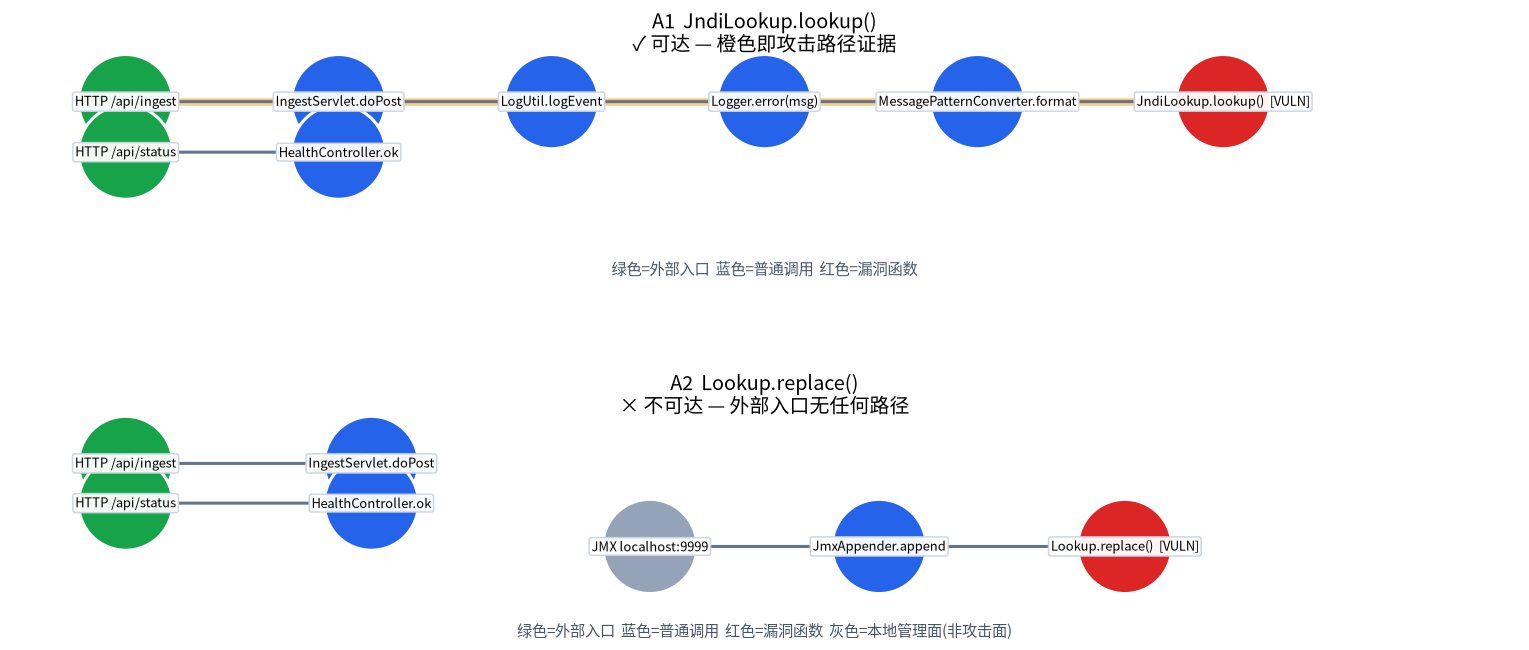

  ✔ out/reachability.png


In [4]:
CALLGRAPHS = {
    "A1": {  # 外部 HTTP → 漏洞函数：可达
        "entries": ["HTTP /api/ingest", "HTTP /api/status"],
        "vuln": "JndiLookup.lookup()  [VULN]",
        "edges": [
            ("HTTP /api/ingest", "IngestServlet.doPost"),
            ("IngestServlet.doPost", "LogUtil.logEvent"),
            ("LogUtil.logEvent", "Logger.error(msg)"),
            ("Logger.error(msg)", "MessagePatternConverter.format"),
            ("MessagePatternConverter.format", "JndiLookup.lookup()  [VULN]"),
            ("HTTP /api/status", "HealthController.ok"),
        ],
    },
    "A2": {  # 漏洞节点存在，但外部入口无路径（仅 JMX 本地子图）→ 不可达
        "entries": ["HTTP /api/ingest", "HTTP /api/status"],
        "vuln": "Lookup.replace()  [VULN]",
        "edges": [
            ("HTTP /api/ingest", "IngestServlet.doPost"),
            ("HTTP /api/status", "HealthController.ok"),
            ("JMX localhost:9999", "JmxAppender.append"),   # 本地管理面，非外部入口
            ("JmxAppender.append", "Lookup.replace()  [VULN]"),
        ],
    },
}


def run_l2(alert_id: str) -> dict:
    fx = CALLGRAPHS.get(alert_id)
    if not fx:
        return {"alert": alert_id, "analyzed": False, "reason": "发行版级/无源码调用图输入"}
    g = nx.DiGraph(fx["edges"])
    path, reached_via = None, None
    for e in fx["entries"]:
        if e in g and nx.has_path(g, e, fx["vuln"]):
            path, reached_via = nx.shortest_path(g, e, fx["vuln"]), e
            break
    ev = {
        "tool": "demo-l2-reach/0.1",
        "graph_snapshot": sid("graph", alert_id, *sorted(fx["edges"])),
        "external_entries": fx["entries"],
        "path": path,
        "vuln_node": fx["vuln"],
    }
    return {
        "alert": alert_id, "analyzed": True,
        "reachable": bool(path),
        "justification_hint": None if path else "vulnerable_code_not_in_execute_path",
        "evidence": ev,
        "snapshot": sid("reach", alert_id, ev["graph_snapshot"]),
    }


reach = {a: run_l2(a) for a in ("A1", "A2", "A3", "A4")}
for aid, r in reach.items():
    if r["analyzed"]:
        print(f"{aid}: {'REACHABLE ✓ → 路径: ' + ' → '.join(r['evidence']['path']) if r['reachable'] else 'UNREACHABLE ✗ (外部入口无路径)'}   [{r['snapshot']}]")
    else:
        print(f"{aid}: 未分析（{r['reason']}）→ under_investigation")


# 手动分层布局：从左(入口)到右(漏洞)，避免 spring 随机乱连
POS = {
    "A1": {
        "HTTP /api/ingest": (0, 1.0),
        "IngestServlet.doPost": (1.3, 1.0),
        "LogUtil.logEvent": (2.6, 1.0),
        "Logger.error(msg)": (3.9, 1.0),
        "MessagePatternConverter.format": (5.2, 1.0),
        "JndiLookup.lookup()  [VULN]": (6.7, 1.0),
        "HTTP /api/status": (0, -0.4),
        "HealthController.ok": (1.3, -0.4),
    },
    "A2": {
        "HTTP /api/ingest": (0, 1.0),
        "IngestServlet.doPost": (1.5, 1.0),
        "HTTP /api/status": (0, -0.1),
        "HealthController.ok": (1.5, -0.1),
        "JMX localhost:9999": (3.2, -1.3),
        "JmxAppender.append": (4.6, -1.3),
        "Lookup.replace()  [VULN]": (6.1, -1.3),
    },
}


def draw_graph(alert_id: str, ax):
    fx = CALLGRAPHS[alert_id]
    g = nx.DiGraph(fx["edges"])
    pos = POS[alert_id]
    colors = []
    for n in g.nodes:
        if n == fx["vuln"]:
            colors.append("#dc2626")
        elif n in fx["entries"]:
            colors.append("#16a34a")
        elif "JMX" in n:
            colors.append("#94a3b8")
        else:
            colors.append("#2563eb")
    r = reach[alert_id]
    title = (f"{alert_id}  {fx['vuln'].split('  ')[0]}\n"
             + ("✓ 可达 — 橙色即攻击路径证据" if r.get("reachable") else "× 不可达 — 外部入口无任何路径"))
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    coll = nx.draw_networkx_nodes(g, pos, ax=ax, node_color=colors, node_size=3800,
                                  edgecolors="white", linewidths=2)
    coll.set_clip_on(False)
    if r.get("reachable"):
        epos = [pos[n] for n in r["evidence"]["path"]]
        xs, ys = zip(*epos)
        ax.plot(xs, ys, color="#f59e0b", lw=5, alpha=0.5, zorder=1, solid_capstyle="round")
    ecoll = nx.draw_networkx_edges(g, pos, ax=ax, edge_color="#64748b",
                                   arrows=True, arrowsize=16, width=2.0)
    for art in ecoll:
        art.set_clip_on(False)
    labels = nx.draw_networkx_labels(
        g, pos, font_size=8.5, font_family=matplotlib.rcParams["font.family"], ax=ax,
        bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="#cbd5e1", alpha=0.95))
    for t in labels.values():
        t.set_clip_on(False)
    ax.text(0.5, -0.42, "绿色=外部入口  蓝色=普通调用  红色=漏洞函数"
            + ("  灰色=本地管理面(非攻击面)" if alert_id == "A2" else ""),
            transform=ax.transAxes, ha="center", fontsize=10, color="#475569")
    ax.set_xlim(-0.7, 8.5)
    ax.set_ylim(-2.1, 1.9)
    ax.axis("off")


fig, axes = plt.subplots(2, 1, figsize=(14, 6.4))
draw_graph("A1", axes[0])
draw_graph("A2", axes[1])
plt.tight_layout(h_pad=3.5)
plt.savefig(OUT / "reachability.png", bbox_inches="tight")
plt.show()
print("  ✔ out/reachability.png")


## ③B 判定 · Exploitability 四轴证据卡 + 优先级

> **一句话结论：** 严重度、概率、利用事实、暴露面**四轴并排给人看**，优先级由**写在纸面上的规则表**推导——可下钻、可争论，拒绝黑箱"风险分"。

四轴并排、**不合成黑箱分**（`report/05 §3.2-3.3`）；建议动作由**透明规则表**给出：

| 规则 | 条件 | 建议 |
|------|------|------|
| R-KEV | KEV ∩ 版本命中（distro 未覆写）| **P0 · 触发 Art.14 事件流** |
| R-UNREACH | 不可达 | P3 · VEX `not_affected`（证据=call path）|
| R-DISTRO | distro=fixed | P2 · VEX `not_affected`（证据=tracker）|
| R-PENDING | 未分析 | P1 · `under_investigation` + SLA 24h |
| R-DEFAULT | 可达且有利用情报 | P1 · 评估缓解/升级 |


In [5]:
by_id = {i["id"]: i for i in INTEL}
distro_by = {i["id"]: i.get("distro") for i in INTEL}

def exposure(aid: str) -> str:
    r = reach.get(aid, {})
    if r.get("reachable"):
        return "互联网可达 (via /api/*)"
    if r.get("analyzed") is False:
        return "未知（未分析）"
    return "仅本地管理面"

cards = []
for aid in ("A1", "A2", "A3", "A4"):
    it, r, db = by_id[aid], reach.get(aid, {}), distro_by.get(aid)
    axes4 = {
        "CVSS(严重度)": it["sources"][0].get("cvss", "—"),
        "EPSS(概率)": it["epss"],
        "KEV(事实)": "✅" if it["kev"] else "—",
        "暴露面": exposure(aid),
    }
    if db and db["status"] == "fixed":
        action, rule = "VEX=not_affected（backport 证据）→ P2", "R-DISTRO"
    elif r.get("analyzed") and not r.get("reachable"):
        action, rule = "VEX=not_affected（call path 证据）→ P3", "R-UNREACH"
    elif not r.get("analyzed"):
        action, rule = "under_investigation + SLA 24h → P1", "R-PENDING"
    elif it["kev"]:
        action, rule = "事件流 Art.14 启动 + VEX=affected → P0", "R-KEV"
    else:
        action, rule = "评估升级/缓解 → P1", "R-DEFAULT"
    cards.append({
        "alert": aid, "cve": it["cve"], "title": it["title"][:34],
        **{f"轴·{k}": v for k, v in axes4.items()},
        "规则": rule, "建议动作": action,
    })

cards_df = pd.DataFrame(cards)
priority = cards_df[["alert", "cve", "规则", "建议动作"]].copy()
cards_df.style.hide(axis="index")


alert,cve,title,轴·CVSS(严重度),轴·EPSS(概率),轴·KEV(事实),轴·暴露面,规则,建议动作
A1,CVE-2021-44228,Log4Shell — JNDI lookup RCE,10.000000,0.976000,✅,互联网可达 (via /api/*),R-KEV,事件流 Art.14 启动 + VEX=affected → P0
A2,CVE-2021-45046,Log4j2 incomplete fix — pattern lo,9.000000,0.214000,—,仅本地管理面,R-UNREACH,VEX=not_affected（call path 证据）→ P3
A3,CVE-2021-4034,pkexec PwnKit LPE,7.800000,0.941000,✅,未知（未分析）,R-DISTRO,VEX=not_affected（backport 证据）→ P2
A4,CVE-2026-42424,[SYNTHETIC] telemetry-sdk 反序列化缺陷（演,8.100000,0.062000,—,未知（未分析）,R-PENDING,under_investigation + SLA 24h → P1


## ④ VEX 判定工作流 — 状态机 + 强制证据 + 人审 + SLA

> **一句话结论：** 每个判定**必须带理由和证据快照**才能落库——AI 只能给建议，人来签字；调查卡超过 24 小时没人管，系统自动升级。

对应 **PoC-3**（`report/08 §3`）：VEX 是"判定工作流"而非"导出格式"（`report/01 §6.3`）。

- 状态：`affected` / `not_affected` / `fixed` / `under_investigation`
- justification 受控词表（CISA 四理由，`report/01 §6.2`）
- **每次迁移强制挂证据快照**（谁/何时/基于什么），无法"裸改状态"
- SLA：`under_investigation` 超 24h → 升级（A4 在 T0+30h 被抓到超时）


In [6]:
VALID_STATUS = {"affected", "not_affected", "fixed", "under_investigation"}
VALID_JUST = {None, "vulnerable_code_not_present", "vulnerable_code_not_in_execute_path",
              "cannot_be_controlled_by_adversary", "inline_mitigations_already_exist"}

def propose(aid: str):
    it, r, db = by_id[aid], reach.get(aid, {}), distro_by.get(aid)
    if db and db["status"] == "fixed":
        return "not_affected", "vulnerable_code_not_present", {
            "why": f"Debian {db['suite']} 已 backport 修复于 {db['fixed_in']}，镜像版本一致 → 缺陷代码不在构建物",
            "src": db["tracker"],
        }
    if not r.get("analyzed"):
        return "under_investigation", None, {"why": "等待 L2 reachability 分析（SLA 24h）", "src": None}
    if not r.get("reachable"):
        return "not_affected", "vulnerable_code_not_in_execute_path", {
            "why": "外部入口集无任何路径抵达漏洞函数", "src": r["snapshot"],
        }
    return "affected", None, {
        "why": f"版本区间命中 + call path 可达（经 {r['evidence']['path'][0]}）" + (" + KEV 在野利用" if it["kev"] else ""),
        "src": r["snapshot"],
    }


judgments = []
for aid in ("A1", "A2", "A3", "A4"):
    status, just, ev = propose(aid)
    assert status in VALID_STATUS and just in VALID_JUST
    actor = "zhang.wei@acme (产品安全 · 人审)"
    j = {
        "judgment_id": f"VEX-{aid}-3.2.1",
        "release": PRODUCT["version"],
        "cve": by_id[aid]["cve"],
        "status": status,
        "justification": just,
        "evidence": ev,
        "decided_by": actor,
        "decided_at": T0.isoformat(),
        "snapshot": sid("judgment", aid, status, just, ev.get("src"), actor),
    }
    judgments.append(j)
    print(f"  {aid} → {status:<20} just={just or '—':<36} [{j['snapshot']}]")

# SLA 升级检查（T_LATE = T0+30h）
print("\n—— SLA 检查 @", T_LATE.isoformat(), "——")
escalated = []
for j, aid in zip(judgments, ("A1", "A2", "A3", "A4")):
    if j["status"] == "under_investigation":
        age_h = (T_LATE - T0).total_seconds() / 3600
        if age_h > 24:
            escalated.append(aid)
            print(f"  ⚠ {aid} ({j['cve']}) investigating 已 {age_h:.0f}h > 24h → 升级至产品安全负责人")

vex_doc = {
    "bomRef": sid("vex-doc", PRODUCT["version"]),
    "spec": "CycloneDX-1.7 vulnerabilities[] (demo)",
    "product": PRODUCT["name"],
    "release": PRODUCT["version"],
    "analysis": [
        {
            "cve": j["cve"],
            "status": j["status"],
            "justification": j["justification"],
            "detail": j["evidence"]["why"],
            "refs": [{"source": "internal-evidence", "id": j["snapshot"]}],
            "timestamp": j["decided_at"],
        }
        for j in judgments
    ],
}
save("vex_v3.2.1.cdx.json", vex_doc)
pd.DataFrame([{k: j[k] for k in ("judgment_id", "cve", "status", "justification", "snapshot")} for j in judgments]).style.hide(axis="index")


  A1 → affected             just=—                                    [snap-9d12525eaa70]
  A2 → not_affected         just=vulnerable_code_not_in_execute_path  [snap-0b19d3dfdc57]
  A3 → not_affected         just=vulnerable_code_not_present          [snap-112203d2b247]
  A4 → under_investigation  just=—                                    [snap-92047b266cb1]

—— SLA 检查 @ 2026-09-23T16:00:00+08:00 ——
  ⚠ A4 (CVE-2026-42424) investigating 已 30h > 24h → 升级至产品安全负责人
  ✔ out/vex_v3.2.1.cdx.json  (1,678 bytes)


judgment_id,cve,status,justification,snapshot
VEX-A1-3.2.1,CVE-2021-44228,affected,nan,snap-9d12525eaa70
VEX-A2-3.2.1,CVE-2021-45046,not_affected,vulnerable_code_not_in_execute_path,snap-0b19d3dfdc57
VEX-A3-3.2.1,CVE-2021-4034,not_affected,vulnerable_code_not_present,snap-112203d2b247
VEX-A4-3.2.1,CVE-2026-42424,under_investigation,nan,snap-92047b266cb1


## ⑤ 处置与验证 — 修复四选 → 升级 → 复扫 → `fixed`

> **一句话结论：** 标 `fixed` 之前**必须复扫验证**——"上游修了"不等于"我的产品修了"，没有复扫证据就不允许改状态。

对应 **J4**（`report/04 §4`）：`fixed` 必须过**验证回路**才能迁移（`report/06 §1/§3-4`）。

- A1 选**升级** log4j-core 2.14.0 → 2.17.1 → Release **3.2.2**
- 复扫：2.17.1 不再落入 `<2.15.0` 区间 → 证据 = SBOM diff + rescan 快照
- A2/A3 无需升级（已 not_affected）；A4 仍 investigating


In [7]:
REMEDIATION = {
    "A1": {"choice": "升级", "from": "2.14.0", "to": "2.17.1", "pr": "acme/gateway#4721", "merged": True},
    "A2": {"choice": "无需处置（VEX not_affected）"},
    "A3": {"choice": "无需处置（发行版 backport 已含修复）"},
    "A4": {"choice": "暂无法处置（调查中）", "mitigation": "telemetry 出网白名单收紧（缓解，非修复）"},
}

# —— 模拟 A1 升级后的复扫 ——
SBOM_V322 = json.loads(json.dumps(SBOM_V321))
SBOM_V322["release"] = "3.2.2"
for c in SBOM_V322["components"]:
    if c["purl"].endswith("log4j-core"):
        c["version"] = "2.17.1"
rescan_rows = []
for it in INTEL:
    if it["component_purl"] != "pkg:maven/org.apache.logging.log4j/log4j-core":
        continue
    for c in SBOM_V322["components"]:
        if c["purl"] == it["component_purl"]:
            still = any(in_range(c["version"], s["range"]) for s in it["sources"])
            rescan_rows.append({"cve": it["cve"], "v3.2.1": "命中", "v3.2.2": "命中" if still else "不再命中 ✓"})

diff_snap = sid("sbom-diff", sbom_snap, json.dumps(SBOM_V322, sort_keys=True))
verify_ok = all("不再命中" in r["v3.2.2"] for r in rescan_rows if r["cve"] == "CVE-2021-44228")

# A1 判定迁移到 fixed（带验证证据）
j_a1 = judgments[0]
if verify_ok:
    j_a1_prev = j_a1["snapshot"]
    j_a1.update({
        "status": "fixed",
        "justification": None,
        "evidence": {"why": f"升级 {REMEDIATION['A1']['from']}→{REMEDIATION['A1']['to']}，复扫不再命中；PR {REMEDIATION['A1']['pr']}", "src": diff_snap},
        "snapshot": sid("judgment", "A1", "fixed", diff_snap),
        "verified_at": T_CHECK.isoformat(),
    })
    print(f"A1 迁移 affected → fixed  （旧 {j_a1_prev} → 新 {j_a1['snapshot']}，证据={diff_snap}）")
else:
    print("A1 验证未通过，状态保持 affected（防止虚假修复声明）")

print("\n复扫对比 (log4j 相关):")
print(pd.DataFrame(rescan_rows).to_string(index=False))
print("\n处置清单:")
print(pd.DataFrame([{"alert": k, **v} for k, v in REMEDIATION.items()]).to_string(index=False))

save("sbom_v3.2.2.json", SBOM_V322)


A1 迁移 affected → fixed  （旧 snap-9d12525eaa70 → 新 snap-659b48bed5ac，证据=snap-4cb376a69180）

复扫对比 (log4j 相关):
           cve v3.2.1 v3.2.2
CVE-2021-44228     命中 不再命中 ✓
CVE-2021-45046     命中 不再命中 ✓

处置清单:
alert                  choice   from     to                pr merged                mitigation
   A1                      升级 2.14.0 2.17.1 acme/gateway#4721   True                       NaN
   A2  无需处置（VEX not_affected）    NaN    NaN               NaN    NaN                       NaN
   A3 无需处置（发行版 backport 已含修复）    NaN    NaN               NaN    NaN                       NaN
   A4              暂无法处置（调查中）    NaN    NaN               NaN    NaN telemetry 出网白名单收紧（缓解，非修复）
  ✔ out/sbom_v3.2.2.json  (891 bytes)


PosixPath('out/sbom_v3.2.2.json')

## ⑥ 事件报告状态机 — Art.14：24h / 72h / ≤14d

> **一句话结论：** KEV 一命中就触发 **24 小时法定报告**——倒计时、字段模板、冻结的 SBOM 快照同时就位；本演示 **提前 18 小时交卷**。

**法条：Art.14，2026-09-11 已生效**（`report/02 §3.1`）。触发条件：KEV/actively exploited 严重事件 → A1。

| 里程碑 | 截止 | 本演示 |
|--------|------|--------|
| T0 发现 + 冻结 SBOM 快照 | — | ✓ |
| 早期预警 24h | T0+24h | 草稿 @ T0+6h（提前 18h）✓ |
| 正式通知 72h | T0+72h | 草稿字段预填 |
| final ≤14d（纠正措施后）| 措施后 14 天 | 模板占位 |

字段结构按报告 `02 §3.1` 表格（真实 SRP 接口 schema = 下一轮研究任务 #1）。


In [8]:
INCIDENT = {
    "incident_id": "INC-2026-0922-001",
    "trigger": "KEV ∩ 产品命中 ∩ actively_exploited → Art.14",
    "cve": "CVE-2021-44228",
    "t0": T0.isoformat(),
    "frozen_sbom": {"release": "3.2.1", "snapshot": sbom_snap},
    "deadlines": {
        "early_warning_24h": (T0 + timedelta(hours=24)).isoformat(),
        "formal_72h": (T0 + timedelta(hours=72)).isoformat(),
        "final_14d": (T0 + timedelta(days=14)).isoformat(),
    },
    "reports": {
        "24h_early_warning": {
            "produced_at": T_CHECK.isoformat(),
            "hours_left": 24 - (T_CHECK - T0).total_seconds() / 3600,
            "fields": {
                "reporting_entity": PRODUCT["manufacturer"],
                "product": f"{PRODUCT['name']} {PRODUCT['version']}",
                "vulnerability": "CVE-2021-44228 (CVSS 10.0, KEV)",
                "discovery": "内部 SCA 关联 KEV 新增条目（情报快照 " + intel_snap + "）",
                "malicious_use": "是 — 已在野利用（KEV）",
                "initial_impact": "远程代码执行；网关管理面经 /api/ingest 可达（L2 证据 " + reach["A1"]["snapshot"] + "）",
                "mitigation": "紧急缓解：禁用 JNDI（log4j2.formatMsgNoLookups=true）+ 出网白名单；正式修复升级中",
                "contacts": "security@acme.example / PSIRT",
            },
        },
        "72h_formal": {
            "produced_at": None,  # 模板预填，待人审
            "fields": {
                "root_cause": "依赖组件缺陷（第三方库）",
                "exploitation": "网络可达；无需认证（/api/ingest）",
                "affected_products": [f"{PRODUCT['name']} {PRODUCT['version']}"],
                "affected_component": "log4j-core 2.14.0 (purl 匹配)",
                "fix_status": f"升级 PR {REMEDIATION['A1']['pr']} → 3.2.2（复扫 {diff_snap}）",
                "cross_border": "面向 EU 多成员国销售 — 需同步成员国 CSIRT（SRP 扇出）",
            },
        },
        "final_14d": {"produced_at": None, "fields": {"status": "待纠正措施完成后 14 天内提交", "sbom_after_fix": "3.2.2 / " + diff_snap}},
    },
}

ew = INCIDENT["reports"]["24h_early_warning"]
remaining = ew["hours_left"]
print(f"事件 {INCIDENT['incident_id']}  T0={INCIDENT['t0']}")
print(f"24h 预警: 产出 {ew['produced_at']}，剩余 {remaining:.0f}h（限期内 ✓）")
print(f"72h 截止: {INCIDENT['deadlines']['formal_72h']}")
print(f"final 截止: {INCIDENT['deadlines']['final_14d']}")
print("冻结 SBOM:", INCIDENT["frozen_sbom"])
save("incident_INC-2026-0922-001.json", INCIDENT)
_dl = INCIDENT["deadlines"]
_rows = [
    {"报告": "24h 早期预警", "截止": _dl["early_warning_24h"], "状态": "草稿完成（限期内）" if INCIDENT["reports"]["24h_early_warning"].get("produced_at") else "待产出"},
    {"报告": "72h 正式通知", "截止": _dl["formal_72h"], "状态": "字段预填待人审" if not INCIDENT["reports"]["72h_formal"].get("produced_at") else "完成"},
    {"报告": "≤14d final", "截止": _dl["final_14d"], "状态": "模板占位" if not INCIDENT["reports"]["final_14d"].get("produced_at") else "完成"},
]
pd.DataFrame(_rows).style.hide(axis="index")


事件 INC-2026-0922-001  T0=2026-09-22T10:00:00+08:00
24h 预警: 产出 2026-09-22T16:00:00+08:00，剩余 18h（限期内 ✓）
72h 截止: 2026-09-25T10:00:00+08:00
final 截止: 2026-10-06T10:00:00+08:00
冻结 SBOM: {'release': '3.2.1', 'snapshot': 'snap-f07fc15cbc73'}
  ✔ out/incident_INC-2026-0922-001.json  (1,943 bytes)


报告,截止,状态
24h 早期预警,2026-09-23T10:00:00+08:00,草稿完成（限期内）
72h 正式通知,2026-09-25T10:00:00+08:00,字段预填待人审
≤14d final,2026-10-06T10:00:00+08:00,模板占位


## ⑦ Evidence Graph — 建图 / 可视化 / 时间旅行 / 客户应答包

> **一句话结论：** 所有步骤沉淀为 **10 年可回放的证据图**——客户要材料时 2 分钟装配出应答包，而不是翻两周聊天记录。

对应 `report/06 §4`：**判定链进图、10 年可回放**（Annex I Pt II(6)）。

三个杀手级查询（`report/06 §4.3`）：
1. **证据链**：A1 的 fixed 判定 ← 依赖哪些快照？
2. **报告完备度**：INC 三份报告字段缺口？
3. **客户应答包**（J5）：SBOM + VEX + 事件状态 → `out/customer_response_pack.md`


findfont: Failed to find font weight bold for Noto Sans CJK SC, now using 400.


证据图: 25 节点, 27 边



findfont: Failed to find font weight bold for Noto Sans CJK SC, now using 400.


findfont: Failed to find font weight bold for Noto Sans CJK SC, now using 400.


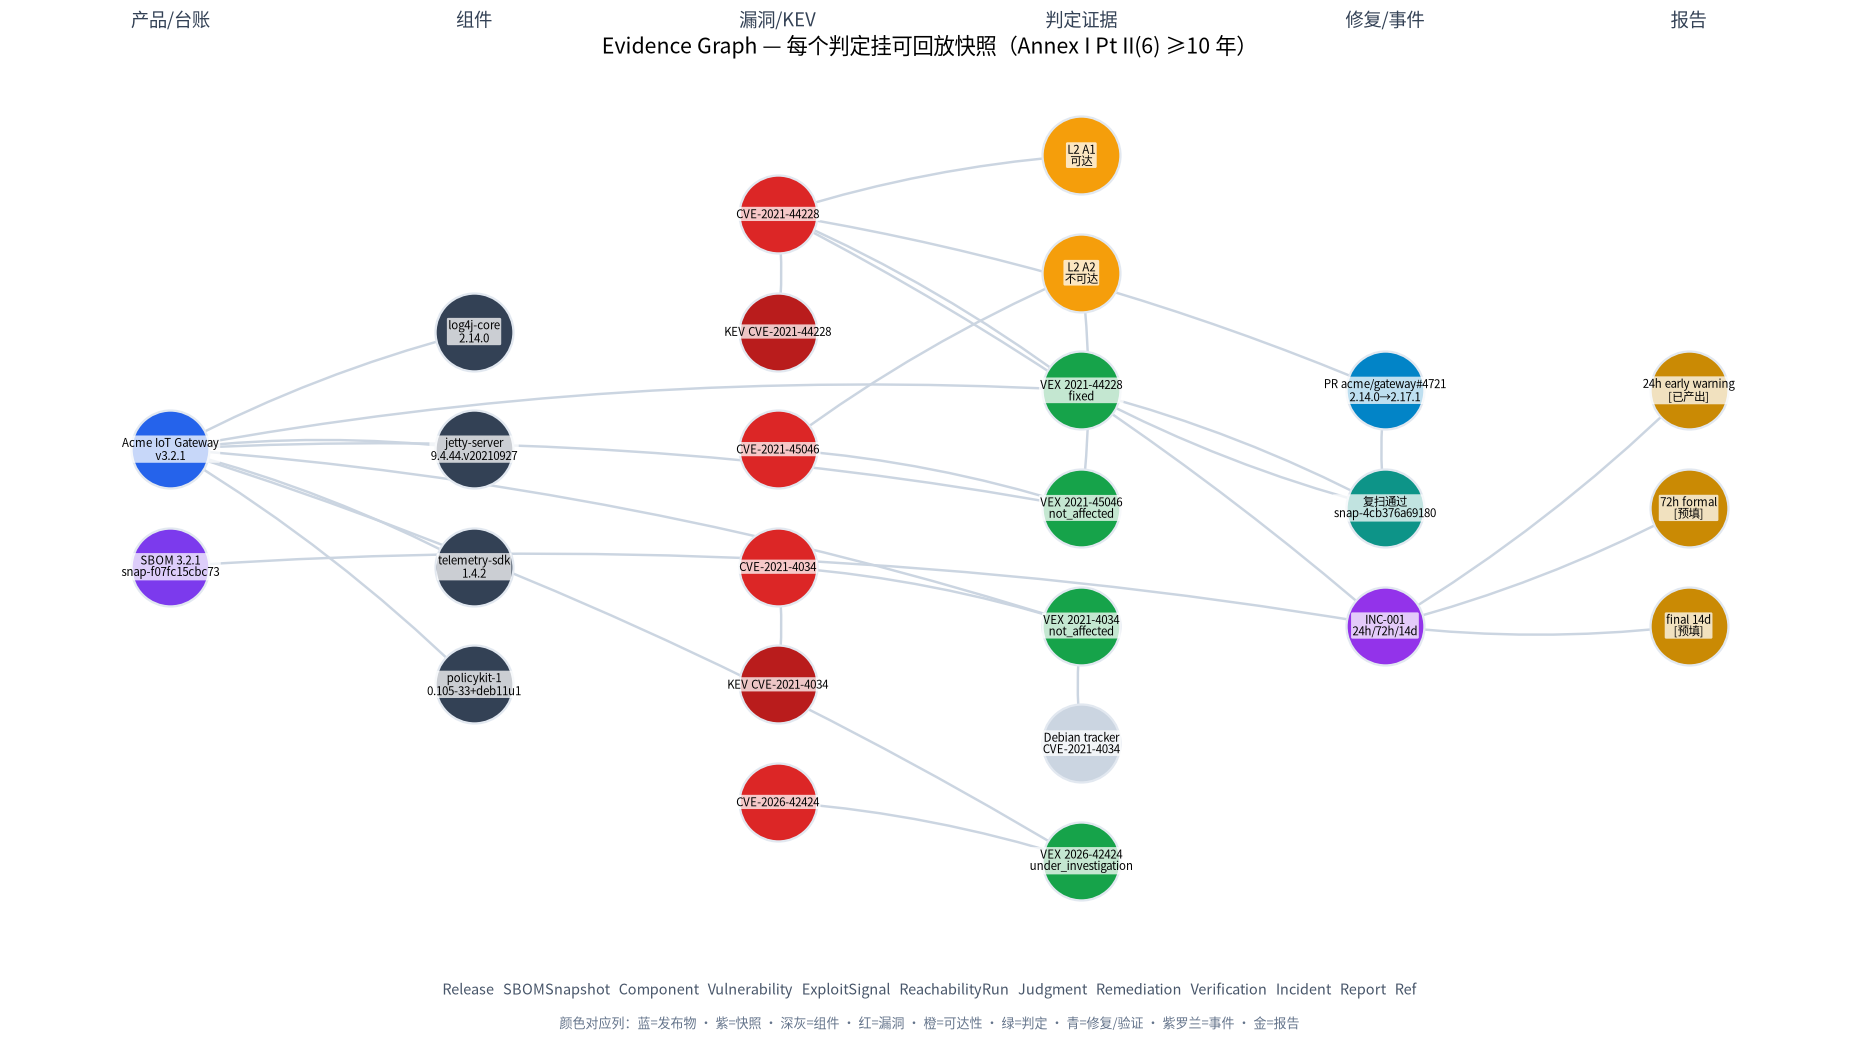

  ✔ out/evidence_graph.png

【查询 1】A1=fixed 判定的证据链:
  Judgment snap-659b48bed5ac (fixed)
    ├─ why: 升级 2.14.0→2.17.1，复扫不再命中；PR acme/gateway#4721
    ├─ evidence src: snap-4cb376a69180
    ├─ incident: INC-2026-0922-001 ← frozen snap-f07fc15cbc73
    └─ 回放: sid(相同输入) 必重现同 snapshot（内容寻址）→ True

【查询 2】INC 报告字段完备度:
  24h_early_warning  ✅ 草稿完成  空字段=无
  72h_formal         ⏳ 模板预填  空字段=无
  final_14d          ⏳ 模板预填  空字段=无

【查询 3】客户应答包已导出 → out/customer_response_pack.md
  ✔ out/evidence_graph.json  (6,185 bytes)


PosixPath('out/evidence_graph.json')

In [9]:
G = nx.DiGraph()

def add(nid, ntype, **attrs):
    G.add_node(nid, ntype=ntype, **attrs)

def link(a, b, rel):
    for n in (a, b):
        if n is not None and n not in G:
            lbl = str(n)
            if "security-tracker.debian.org" in lbl:
                lbl = "Debian tracker\nCVE-2021-4034"
            else:
                lbl = lbl.split("/")[-1][:18]
            G.add_node(n, ntype="Ref", label=lbl)
    if a is not None and b is not None:
        G.add_edge(a, b, rel=rel)

# 实体（产品级模型）
add(PRODUCT["version"], "Release", label=f"{PRODUCT['name']}\nv{PRODUCT['version']}")
add(sbom_snap, "SBOMSnapshot", label=f"SBOM 3.2.1\n{sbom_snap}")
for c in SBOM_V321["components"]:
    cid = c["purl"] + "@" + c["version"]
    add(cid, "Component", label=c["purl"].split("/")[-1] + "\n" + c["version"])
    link(cid, PRODUCT["version"], "in_release")

for aid, it in by_id.items():
    add(it["cve"], "Vulnerability", label=it["cve"])
    if aid in reach and reach[aid].get("analyzed"):
        rid = reach[aid]["snapshot"]
        add(rid, "ReachabilityRun", label=f"L2 {aid}\n{'可达' if reach[aid]['reachable'] else '不可达'}")
        link(rid, it["cve"], "analyzes")
    if it["kev"]:
        kid = "KEV:" + it["cve"]
        add(kid, "ExploitSignal", label="KEV " + it["cve"])
        link(kid, it["cve"], "in_kev")

rem = REMEDIATION["A1"]
add("PR:" + rem["pr"], "Remediation", label=f"PR {rem['pr']}\n{rem['from']}→{rem['to']}")
link("PR:" + rem["pr"], "CVE-2021-44228", "fixes")
add(diff_snap, "Verification", label=f"复扫通过\n{diff_snap}")
link("PR:" + rem["pr"], diff_snap, "verified_by")

for j in judgments:
    add(j["snapshot"], "Judgment", label=f"VEX {j['cve'].replace('CVE-', '')}\n{j['status']}")
    link(j["snapshot"], j["cve"], "judges")
    link(j["snapshot"], PRODUCT["version"], "for_release")
    if j["evidence"].get("src"):
        link(j["snapshot"], j["evidence"]["src"], "evidence_from")
link(diff_snap, judgments[0]["snapshot"], "supports")

inc_id = INCIDENT["incident_id"]
add(inc_id, "Incident", label="INC-001\n24h/72h/14d")
link(inc_id, "CVE-2021-44228", "triggered_by")
link(inc_id, sbom_snap, "frozen_sbom")
for rname in INCIDENT["reports"]:
    rid = f"RPT:{rname}"
    done = INCIDENT["reports"][rname].get("produced_at")
    add(rid, "Report", label=rname.replace("_", " ") + ("\n[已产出]" if done else "\n[预填]"))
    link(inc_id, rid, "produces")

print(f"证据图: {G.number_of_nodes()} 节点, {G.number_of_edges()} 边\n")
nt_color = {
    "Release": "#2563eb", "SBOMSnapshot": "#7c3aed", "Component": "#334155",
    "Vulnerability": "#dc2626", "ReachabilityRun": "#f59e0b", "ExploitSignal": "#b91c1c",
    "Judgment": "#16a34a", "Remediation": "#0284c7", "Verification": "#0d9488",
    "Incident": "#9333ea", "Report": "#ca8a04", "Ref": "#cbd5e1",
}
# 六列分层：台账 → 组件 → 漏洞 → 判定 → 处置/事件 → 报告
_col_x = {
    "Release": 0, "SBOMSnapshot": 0,
    "Component": 1,
    "Vulnerability": 2, "ExploitSignal": 2,
    "ReachabilityRun": 3, "Judgment": 3, "Ref": 3,
    "Remediation": 4, "Verification": 4, "Incident": 4,
    "Report": 5,
}
_col_nodes: dict[int, list] = {}
for n, d in G.nodes(data=True):
    _col_nodes.setdefault(_col_x.get(d["ntype"], 3), []).append(n)
pos = {}
for x, nodes in _col_nodes.items():
    for i, n in enumerate(nodes):
        pos[n] = (x * 2.35, -(i - (len(nodes) - 1) / 2) * 1.05)

fig, ax = plt.subplots(figsize=(17, 9.5))
by_type: dict[str, list] = {}
for n, d in G.nodes(data=True):
    by_type.setdefault(d["ntype"], []).append(n)
for ntype, nodes in by_type.items():
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=nt_color.get(ntype, "#bbb"),
                           node_size=2600, ax=ax, edgecolors="#e2e8f0", linewidths=1.5)
nx.draw_networkx_edges(G, pos, edge_color="#cbd5e1", arrows=True, arrowsize=16, width=1.6, ax=ax,
                       connectionstyle="arc3,rad=0.06")
nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, "label"),
                        font_size=7.5, font_family=matplotlib.rcParams["font.family"], ax=ax,
                        bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.75))
for x, name in enumerate(["产品/台账", "组件", "漏洞/KEV", "判定证据", "修复/事件", "报告"]):
    ax.text(x * 2.35, max(p[1] for p in pos.values()) + 1.15, name,
            ha="center", fontsize=12, fontweight="bold", color="#334155")
_order = ["Release", "SBOMSnapshot", "Component", "Vulnerability", "ExploitSignal",
          "ReachabilityRun", "Judgment", "Remediation", "Verification",
          "Incident", "Report", "Ref"]
# 图例：仅彩色文字（不画色块，避免缩放/裁剪问题）
leg = "   ".join(_order)
ax.text(0.5, -0.055, leg, transform=ax.transAxes, ha="center", va="top",
        fontsize=9.5, fontweight="bold", color="#475569")
# 逐词上色（近似位置着色较难，这里用说明行代替）
ax.text(0.5, -0.095, "颜色对应列：蓝=发布物 · 紫=快照 · 深灰=组件 · 红=漏洞 · 橙=可达性 · 绿=判定 · 青=修复/验证 · 紫罗兰=事件 · 金=报告",
        transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#64748b")
ax.set_title("Evidence Graph — 每个判定挂可回放快照（Annex I Pt II(6) ≥10 年）",
             fontsize=14, fontweight="bold", pad=18)
ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "evidence_graph.png", bbox_inches="tight")
plt.show()
print("  ✔ out/evidence_graph.png")

# —— 查询 1: 时间旅行 / 证据链 ——
print("\n【查询 1】A1=fixed 判定的证据链:")
j = judgments[0]
print(f"  Judgment {j['snapshot']} ({j['status']})")
print(f"    ├─ why: {j['evidence']['why']}")
print(f"    ├─ evidence src: {j['evidence'].get('src')}")
print(f"    ├─ incident: {inc_id} ← frozen {sbom_snap}")
print(f"    └─ 回放: sid(相同输入) 必重现同 snapshot（内容寻址）→ {sid('judgment', 'A1', 'fixed', diff_snap) == j['snapshot']}")

# —— 查询 2: 报告完备度 ——
print("\n【查询 2】INC 报告字段完备度:")
gaps = []
for rname, r in INCIDENT["reports"].items():
    empty = [k for k, v in r["fields"].items() if v in (None, "", "—")]
    status = "✅ 草稿完成" if r.get("produced_at") else ("⏳ 模板预填" if not empty else "❌ 缺字段")
    print(f"  {rname:<18} {status}  空字段={empty or '无'}")
    gaps.extend(f"{rname}.{k}" for k in empty)

# —— 查询 3: 客户应答包 (J5) ——
vex_rows = "\n".join(
    f"| {j['cve']} | **{j['status']}** | {(j['justification'] or j['evidence']['why'][:40])} | `{j['snapshot']}` |"
    for j in judgments
)
pack_lines = [
    f"# 客户应答包 · {PRODUCT['name']} v{PRODUCT['version']}",
    f"生成: {T_CHECK.isoformat()}（证据链可点验）",
    "",
    "## 1. 支持期声明（Annex I Pt II(3)）",
    f"- 支持至 **{PRODUCT['support_until']}**（≥5 年）",
    "",
    "## 2. SBOM 快照",
    f"- snapshot: `{sbom_snap}` · 组件 {len(SBOM_V321['components'])} 个 · 质量分 {q['score']}/100",
    "- 格式: CycloneDX-1.7（另附 SPDX 见 out/）",
    "",
    "## 3. 漏洞判定（VEX 摘要）",
    "| CVE | 状态 | 理由 | 证据 |",
    "|-----|------|------|------|",
    vex_rows,
    "",
    "## 4. 事件状态（Art.14）",
    f"- {inc_id}: 24h 预警 **已产出**（{ew['produced_at']}，限期内）；72h 预填；final 模板就绪",
    "",
    "## 5. 修复",
    f"- log4j-core 2.14.0 → 2.17.1（PR {rem['pr']}，复扫证据 `{diff_snap}`）",
    "",
    "> 本包由 Evidence Graph 装配；每个 snapshot 可在 10 年留存期内回放校验。",
]
(OUT / "customer_response_pack.md").write_text("\n".join(pack_lines), encoding="utf-8")
print("\n【查询 3】客户应答包已导出 → out/customer_response_pack.md")

graph_json = nx.node_link_data(G)
save("evidence_graph.json", graph_json)


## ⑧ 收尾 — 阶段 × 法条 × 产物映射（回看图 A/B）

> **一句话结论：** 七个阶段全部走通；每一行产物都能指回一条 CRA 法条——**这不是功能清单，是合规证据链**。


In [10]:
summary = pd.DataFrame([
    {"阶段": "① 摄取", "法条": "Annex I Pt II(1)(3)", "本笔记本产物": f"SBOM {sbom_snap} · 质量 {q['score']}/100 · 支持期台账", "文件": "—"},
    {"阶段": "② 关联", "法条": "Annex I Pt II(1)", "本笔记本产物": f"4 告警 · 五层 match-explain · 情报快照 {intel_snap}", "文件": "—"},
    {"阶段": "③A 判定-可达", "法条": "exploitable 推导", "本笔记本产物": "A1 可达路径 / A2 不可达证据 · L2 运行快照", "文件": "out/reachability.png"},
    {"阶段": "③B 判定-四轴", "法条": "Art.14 触发参考", "本笔记本产物": "四轴证据卡 + 透明规则 R-KEV/UNREACH/DISTRO/PENDING", "文件": "—"},
    {"阶段": "④ VEX", "法条": "VEX 语义 (01 §6)", "本笔记本产物": "4 判定(含人审) · SLA 升级 A4 · 状态机断言通过", "文件": "out/vex_v3.2.1.cdx.json"},
    {"阶段": "⑤ 处置", "法条": "Annex I Pt II(2)(4)", "本笔记本产物": "A1 升级→复扫→fixed · 3.2.2 SBOM", "文件": "out/sbom_v3.2.2.json"},
    {"阶段": "⑥ 报告", "法条": "Art.14 (已生效)", "本笔记本产物": "INC-001 · 24h 草稿(剩余 %.0fh) · 72h/14d 预填" % remaining, "文件": "out/incident_INC-2026-0922-001.json"},
    {"阶段": "⑦ 留证", "法条": "Annex I Pt II(6)", "本笔记本产物": f"证据图 {G.number_of_nodes()} 节点 · 3 查询 · 应答包", "文件": "out/evidence_graph.png, customer_response_pack.md"},
])
print("=" * 100)
print("全流程演示完成 —— 图 B 七个阶段全部走通，快照内容寻址、可回放")
print("=" * 100)
summary.to_string(index=False)


全流程演示完成 —— 图 B 七个阶段全部走通，快照内容寻址、可回放


'      阶段                  法条                                           本笔记本产物                                                文件\n    ① 摄取 Annex I Pt II(1)(3)      SBOM snap-f07fc15cbc73 · 质量 100/100 · 支持期台账                                                 —\n    ② 关联    Annex I Pt II(1) 4 告警 · 五层 match-explain · 情报快照 snap-386da88c38db                                                 —\n③A 判定-可达      exploitable 推导                     A1 可达路径 / A2 不可达证据 · L2 运行快照                              out/reachability.png\n③B 判定-四轴         Art.14 触发参考        四轴证据卡 + 透明规则 R-KEV/UNREACH/DISTRO/PENDING                                                 —\n   ④ VEX      VEX 语义 (01 §6)                  4 判定(含人审) · SLA 升级 A4 · 状态机断言通过                           out/vex_v3.2.1.cdx.json\n    ⑤ 处置 Annex I Pt II(2)(4)                      A1 升级→复扫→fixed · 3.2.2 SBOM                              out/sbom_v3.2.2.json\n    ⑥ 报告        Art.14 (已生效)            INC-001 · 24h 草稿(剩余 18h) · 72h/14d 预填               out/